# Experiment No. 4 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Implement K-Means clustering on Iris.csv dataset. Determine the number of clusters using the elbow method.

**Dataset Link:**  
`https://www.kaggle.com/datasets/uciml/iris` (Iris Species Dataset, 150 samples, 4 features).

**Objectives:**  
1. Load and inspect the `Iris.csv` dataset.
2. Extract feature attributes (`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`) for unsupervised clustering.
3. Calculate Within-Cluster Sum of Squares (WCSS / Inertia) for cluster values $K = 1$ to $10$.
4. Plot the Elbow Curve to identify the optimal number of clusters ($K = 3$).
5. Fit the K-Means clustering algorithm with $K = 3$ and assign data points to clusters.
6. Visualize the clusters along with their centroids in a 2D scatter plot.

In [1]:
# Cell 1 - Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
# Cell 2 - Load and Inspect Dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/iris.csv"
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# Select numerical features
X = df.drop(columns=['Species', 'Name', 'Id'], errors='ignore')

print("\nFeatures Used:")
print(X.columns.tolist())

Dataset Shape: (150, 5)

First 5 Rows:
   SepalLength  SepalWidth  PetalLength  PetalWidth         Name
0          5.1         3.5          1.4         0.2  Iris-setosa
1          4.9         3.0          1.4         0.2  Iris-setosa
2          4.7         3.2          1.3         0.2  Iris-setosa
3          4.6         3.1          1.5         0.2  Iris-setosa
4          5.0         3.6          1.4         0.2  Iris-setosa

Features Used:
['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth']


C:\Users\bsais\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\bsais\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^

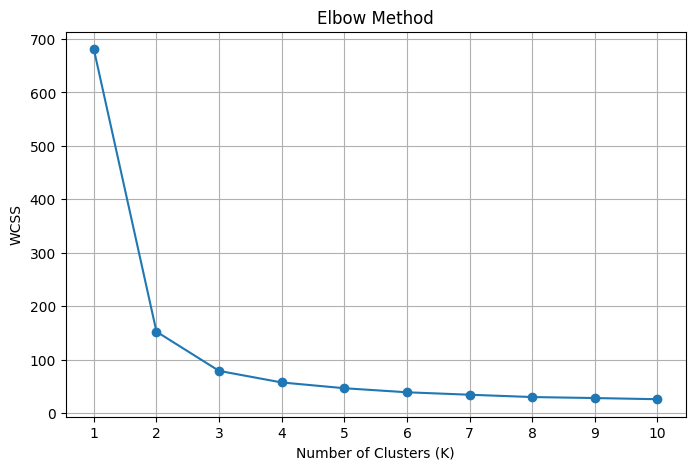

In [3]:
# Cell 3 - Elbow Method to Find Optimal K
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [4]:
# Cell 4 - Apply K-Means Clustering (K = 3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_kmeans = kmeans.fit_predict(X)

df['Cluster'] = y_kmeans

print("\nCluster Assignments:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster Centroids:")
print(pd.DataFrame(kmeans.cluster_centers_, columns=X.columns))


Cluster Assignments:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64

Cluster Centroids:
   SepalLength  SepalWidth  PetalLength  PetalWidth
0     5.901613    2.748387     4.393548    1.433871
1     5.006000    3.418000     1.464000    0.244000
2     6.850000    3.073684     5.742105    2.071053


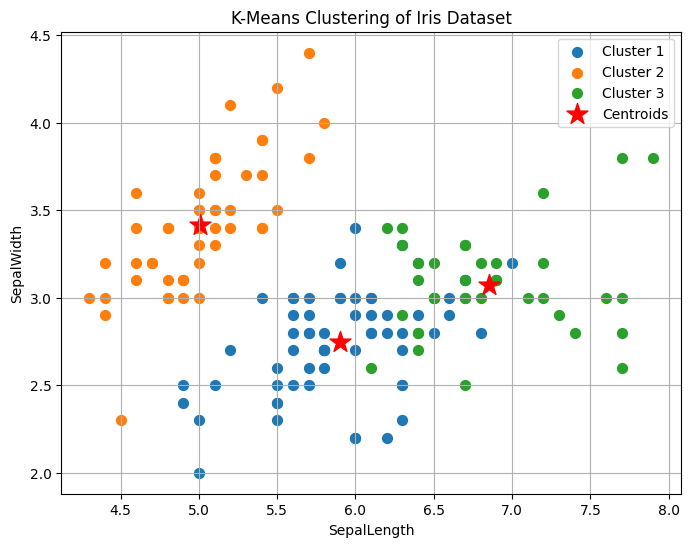

In [5]:
# Cell 5 - Visualize Clusters and Centroids
plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        X.iloc[y_kmeans == i, 0],
        X.iloc[y_kmeans == i, 1],
        label=f'Cluster {i+1}',
        s=50
    )

# Plot centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='*',
    s=250,
    c='red',
    label='Centroids'
)

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clustering of Iris Dataset")
plt.legend()
plt.grid()
plt.show()